In [1]:
%load_ext autoreload
%autoreload 2

# 1 IMPORT LIBRARIES

In [2]:
import pandas as pd
import numpy as np
# Plot Cumulative Returns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import make_scorer, recall_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import os
from xgboost import XGBClassifier
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV


# 2. DATA EXPLORATION

In [21]:
#data = pd.read_excel('./data/ASSURANCE VIE.xlsx', sheet_name='VIXHISTORIQUEMODEL')
usecols_l=list(range(0, 10))


In [22]:
data = pd.read_excel('data/ASSURANCE VIE.xlsx', sheet_name='VIX HISTORIQUE', skiprows=3, usecols=usecols_l)

In [23]:
data

,Date,Close,Date.1,Close.1,Date.2,Close.2,Date.3,Close.3,Date.4,Close.4
0,2018-06-08 16:00:00.288,2779.03,2018-06-08 15:15:59.904,12.18,2018-06-08 15:15:59.904,14.60,2018-06-08 15:15:59.904,16.13,2018-06-08 15:15:59.904,17.23
1,2018-06-11 16:00:00.288,2782.00,2018-06-11 15:15:59.904,12.35,2018-06-11 15:15:59.904,14.55,2018-06-11 15:15:59.904,16.12,2018-06-11 15:15:59.904,17.17
2,2018-06-12 16:00:00.288,2786.85,2018-06-12 15:15:59.904,12.34,2018-06-12 15:15:59.904,14.59,2018-06-12 15:15:59.904,16.17,2018-06-12 15:15:59.904,17.23
3,2018-06-13 16:00:00.288,2775.63,2018-06-13 15:15:59.904,12.94,2018-06-13 15:15:59.904,14.92,2018-06-13 15:15:59.904,16.43,2018-06-13 15:15:59.904,17.44
4,2018-06-14 16:00:00.288,2782.49,2018-06-14 15:15:59.904,12.12,2018-06-14 15:15:59.904,14.40,2018-06-14 15:15:59.904,16.09,2018-06-14 15:15:59.904,17.31
...,...,...,...,...,...,...,...,...,...,...
1620,2024-11-25 16:00:00.288,5987.37,2024-11-22 15:15:59.904,15.24,2024-11-22 15:15:59.904,17.30,2024-11-25 15:15:59.904,18.44,2024-11-25 15:15:59.904,20.06
1621,2024-11-26 16:00:00.288,6021.63,2024-11-25 15:15:59.904,14.60,2024-11-25 15:15:59.904,16.87,2024-11-26 15:15:59.904,18.17,2024-11-26 15:15:59.904,19.89
1622,2024-11-27 16:00:00.288,5998.74,2024-11-26 15:15:59.904,14.10,2024-11-26 15:15:59.904,16.53,2024-11-27 15:15:59.904,18.28,2024-11-27 15:15:59.904,20.03
1623,2024-11-29 13:00:00.288,6032.38,2024-11-27 15:15:59.904,14.10,2024-11-27 15:15:59.904,16.60,2024-11-29 13:00:00.288,18.15,2024-11-29 13:00:00.288,19.74


In [24]:
# Define the list of non-date column names
column_names = ['SPX', 'VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y']





In [25]:
def align_df_dates(data, column_names):
# Split into 5 DataFrames
    dfs = []  # List to store the DataFrames
    for i, col_name in enumerate(column_names):
        # Select Date and corresponding column
        df = data.iloc[:, [i * 2, i * 2 + 1]].copy()  # Every second column (Date, Close)
        df.columns = ['Date', col_name]  # Rename columns
        df['Date'] = pd.to_datetime(df['Date']).dt.strftime('%Y-%m-%d')  # Convert Date column to datetime
        df = df.set_index('Date')
        df.dropna(inplace=True)  # Drop rows with missing values
        dfs.append(df)
        # Start with the first DataFrame (dfs[0]) as the base
        merged_df = dfs[0]
        
        # Iteratively merge other DataFrames based on the index
        for df in dfs[1:]:
            merged_df = merged_df.join(df, how='inner')  # Inner join to align on the index
    return merged_df

In [26]:
data= align_df_dates(data, column_names)


In [27]:
data

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y
Date,,,,,
2018-06-08,2779.03,12.18,14.60,16.13,17.23
2018-06-11,2782.00,12.35,14.55,16.12,17.17
2018-06-12,2786.85,12.34,14.59,16.17,17.23
2018-06-13,2775.63,12.94,14.92,16.43,17.44
2018-06-14,2782.49,12.12,14.40,16.09,17.31
...,...,...,...,...,...
2024-11-22,5969.34,15.24,17.30,18.78,20.26
2024-11-25,5987.37,14.60,16.87,18.44,20.06
2024-11-26,6021.63,14.10,16.53,18.17,19.89


In [28]:
data_open= pd.read_excel('data/ASSURANCE VIE.xlsx', sheet_name='VIX HISTORIQUE OPEN', skiprows=3, usecols=usecols_l)

In [29]:
open_column_names = ['SPX_OPEN', 'VIX1M_OPEN', 'VIX3M_OPEN', 'VIX6M_OPEN', 'VIX1Y_OPEN']

In [30]:
data_open=align_df_dates(data_open, open_column_names)

In [31]:
data_open

,SPX_OPEN,VIX1M_OPEN,VIX3M_OPEN,VIX6M_OPEN,VIX1Y_OPEN
Date,,,,,
2018-06-08,2765.84,12.54,14.90,16.44,17.49
2018-06-11,2780.18,12.52,14.69,16.19,17.24
2018-06-12,2785.60,12.29,14.52,16.14,17.19
2018-06-13,2787.94,12.13,14.45,16.08,17.16
2018-06-14,2783.21,12.98,14.44,16.09,17.19
...,...,...,...,...,...
2024-11-22,5944.36,16.85,17.96,19.18,20.63
2024-11-25,5992.28,15.23,17.05,18.51,20.04
2024-11-26,6000.03,14.56,16.80,18.31,20.04


In [32]:
data_merged=data.join(data_open, how='inner') 

In [33]:
data_merged

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_OPEN,VIX1M_OPEN,VIX3M_OPEN,VIX6M_OPEN,VIX1Y_OPEN
Date,,,,,,,,,,
2018-06-08,2779.03,12.18,14.60,16.13,17.23,2765.84,12.54,14.90,16.44,17.49
2018-06-11,2782.00,12.35,14.55,16.12,17.17,2780.18,12.52,14.69,16.19,17.24
2018-06-12,2786.85,12.34,14.59,16.17,17.23,2785.60,12.29,14.52,16.14,17.19
2018-06-13,2775.63,12.94,14.92,16.43,17.44,2787.94,12.13,14.45,16.08,17.16
2018-06-14,2782.49,12.12,14.40,16.09,17.31,2783.21,12.98,14.44,16.09,17.19
...,...,...,...,...,...,...,...,...,...,...
2024-11-22,5969.34,15.24,17.30,18.78,20.26,5944.36,16.85,17.96,19.18,20.63
2024-11-25,5987.37,14.60,16.87,18.44,20.06,5992.28,15.23,17.05,18.51,20.04
2024-11-26,6021.63,14.10,16.53,18.17,19.89,6000.03,14.56,16.80,18.31,20.04


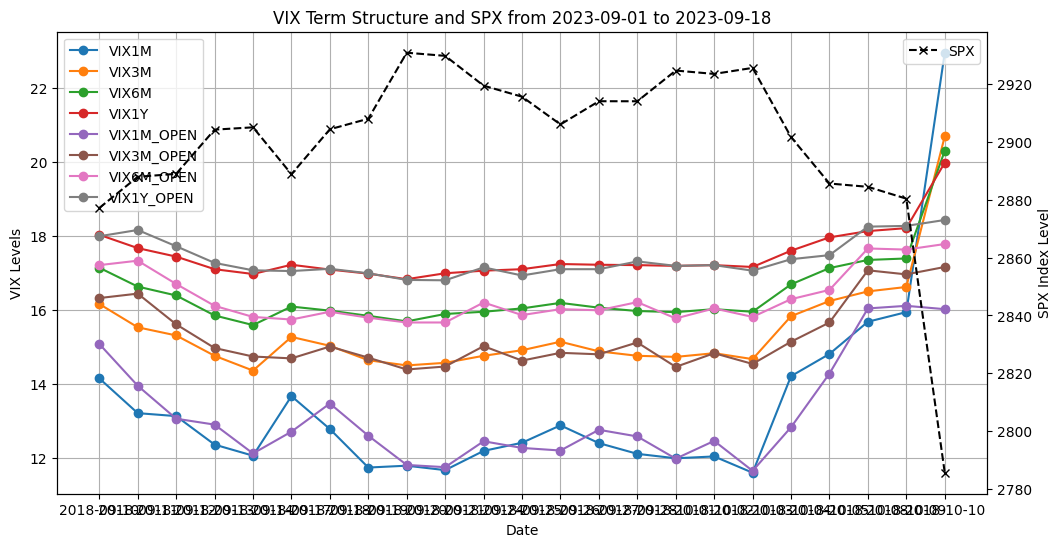

In [37]:
date_range_df = data_merged.loc['2018-09-10':'2018-10-10']  # Filter by date range

# Create the main plot for VIX columns
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot VIX columns
ax1.plot(date_range_df.index, date_range_df['VIX1M'], label='VIX1M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX3M'], label='VIX3M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX6M'], label='VIX6M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX1Y'], label='VIX1Y', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX1M_OPEN'], label='VIX1M_OPEN', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX3M_OPEN'], label='VIX3M_OPEN', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX6M_OPEN'], label='VIX6M_OPEN', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX1Y_OPEN'], label='VIX1Y_OPEN', marker='o')

# Label for the VIX axis
ax1.set_ylabel("VIX Levels")
ax1.set_xlabel("Date")
ax1.legend(loc="upper left")
ax1.grid()

# Create a second y-axis for SPX
ax2 = ax1.twinx()
ax2.plot(date_range_df.index, date_range_df['SPX'], label='SPX', color='black', linestyle='--', marker='x')
ax2.set_ylabel("SPX Index Level")
ax2.legend(loc="upper right")

# Add title
plt.title("VIX Term Structure and SPX from 2023-09-01 to 2023-09-18")

plt.savefig("VIX Crash analysis.png", dpi=300, bbox_inches="tight")


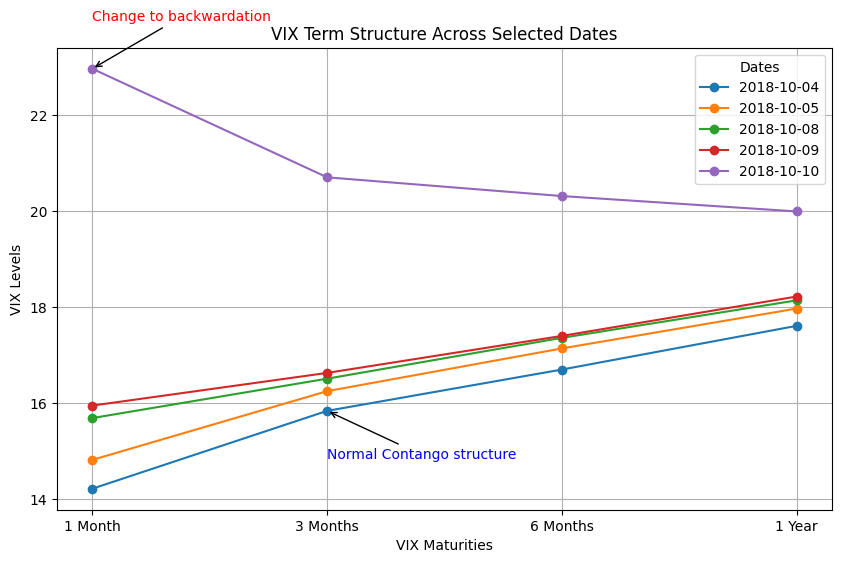

In [17]:
# Specify dates to plot the term structure for
selected_dates = ['2018-10-04', '2018-10-05', '2018-10-08', '2018-10-09', '2018-10-10']
vix_maturities = ['VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y']
maturity_labels = ['1 Month', '3 Months', '6 Months', '1 Year']

# Transpose the data for easier plotting
vix_data_transposed = data.loc[selected_dates, vix_maturities].transpose()

# Plot VIX term structure with maturities as X-axis
fig, ax = plt.subplots(figsize=(10, 6))

for date in selected_dates:
    ax.plot(maturity_labels, vix_data_transposed[date], marker='o', label=f"{date}")

# Highlight the VIX1M value for the last date
last_date = selected_dates[-1]
last_vix1m_value = vix_data_transposed.loc['VIX1M', last_date]
ax.annotate(
    "Change to backwardation",  # Annotation text
    xy=('1 Month', last_vix1m_value),  # Point being annotated
    xytext=('1 Month', last_vix1m_value + 1),  # Position of the text (numeric value)
    arrowprops=dict(facecolor='red', arrowstyle='->'),  # Arrow properties
    fontsize=10,
    color='red'
)

# Highlight the VIX3M value for the firt date: normal contango
first_date = selected_dates[0]
first_vix3m_value = vix_data_transposed.loc['VIX3M', first_date]
ax.annotate(
    "Normal Contango structure",  # Annotation text
    xy=('3 Months', first_vix3m_value),  # Point being annotated
    xytext=('3 Months', first_vix3m_value-1 ),  # Adjust upward for text placement
    arrowprops=dict(facecolor='red', arrowstyle='->'),  # Arrow properties
    fontsize=10,
    color='blue'
)


# Customize plot
ax.set_xlabel("VIX Maturities")
ax.set_ylabel("VIX Levels")
ax.set_title("VIX Term Structure Across Selected Dates")
ax.legend(title="Dates")
ax.grid()

# Save and show the plot
plt.savefig("./results/VIX_Term_Structure_Maturities.png", dpi=300, bbox_inches="tight")
plt.show()


# 3. FINAL 2 STAGE MODEL

## 3.1 STAGE 1 VIX SHIFT PREDICTION

### 3.1.1. VIX DATA FEATURISATION

In [33]:
vix_data= data_merged.copy()
CRASH_DAYS=5

In [34]:
# Calculate slopes (differences) between VIX maturities
vix_data['Slope_1M_3M'] = vix_data['VIX1M_OPEN'] - vix_data['VIX3M_OPEN']
vix_data['Slope_3M_6M'] = vix_data['VIX3M_OPEN'] - vix_data['VIX6M_OPEN']
vix_data['Slope_6M_1Y'] = vix_data['VIX6M_OPEN'] - vix_data['VIX1Y_OPEN']



In [35]:
# Calculate the change as the difference between today's open and the previous day's close
vix_data['SPX_Change'] = vix_data['SPX__OPEN'] - vix_data['SPX'].shift(1)
vix_data['VIX1M_Change'] = vix_data['VIX1M_OPEN'] - vix_data['VIX1M'].shift(CRASH_DAYS)
vix_data['VIX3M_Change'] = vix_data['VIX3M_OPEN'] - vix_data['VIX3M'].shift(CRASH_DAYS)
vix_data['VIX6M_Change'] = vix_data['VIX6M_OPEN'] - vix_data['VIX6M'].shift(CRASH_DAYS)
vix_data['VIX1Y_Change'] = vix_data['VIX1Y_OPEN'] - vix_data['VIX1Y'].shift(CRASH_DAYS)



In [36]:
# Calculate the same-day change for SPX and VIX indices
vix_data['SPX_Same_Day_Change'] = vix_data['SPX'] - vix_data['SPX__OPEN']
vix_data['VIX1M_Same_Day_Change'] = vix_data['VIX1M'] - vix_data['VIX1M_OPEN']
vix_data['VIX3M_Same_Day_Change'] = vix_data['VIX3M'] - vix_data['VIX3M_OPEN']
vix_data['VIX6M_Same_Day_Change'] = vix_data['VIX6M'] - vix_data['VIX6M_OPEN']
vix_data['VIX1Y_Same_Day_Change'] = vix_data['VIX1Y'] - vix_data['VIX1Y_OPEN']


In [37]:
vix_data

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX__OPEN,VIX1M_OPEN,VIX3M_OPEN,VIX6M_OPEN,VIX1Y_OPEN,...,SPX_Change,VIX1M_Change,VIX3M_Change,VIX6M_Change,VIX1Y_Change,SPX_Same_Day_Change,VIX1M_Same_Day_Change,VIX3M_Same_Day_Change,VIX6M_Same_Day_Change,VIX1Y_Same_Day_Change
Date,,,,,,,,,,,,,,,,,,,,,
2018-06-08,2779.03,12.18,14.60,16.13,17.23,2765.84,12.54,14.90,16.44,17.49,...,NaN,NaN,NaN,NaN,NaN,13.19,-0.36,-0.30,-0.31,-0.26
2018-06-11,2782.00,12.35,14.55,16.12,17.17,2780.18,12.52,14.69,16.19,17.24,...,1.15,NaN,NaN,NaN,NaN,1.82,-0.17,-0.14,-0.07,-0.07
2018-06-12,2786.85,12.34,14.59,16.17,17.23,2785.60,12.29,14.52,16.14,17.19,...,3.60,NaN,NaN,NaN,NaN,1.25,0.05,0.07,0.03,0.04
2018-06-13,2775.63,12.94,14.92,16.43,17.44,2787.94,12.13,14.45,16.08,17.16,...,1.09,NaN,NaN,NaN,NaN,-12.31,0.81,0.47,0.35,0.28
2018-06-14,2782.49,12.12,14.40,16.09,17.31,2783.21,12.98,14.44,16.09,17.19,...,7.58,NaN,NaN,NaN,NaN,-0.72,-0.86,-0.04,0.00,0.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-21,5948.71,16.87,18.18,19.41,20.63,5940.58,16.54,17.62,18.93,20.54,...,23.47,2.23,0.94,0.36,0.35,8.13,0.33,0.56,0.48,0.09
2024-11-22,5969.34,15.24,17.30,18.78,20.26,5944.36,16.85,17.96,19.18,20.63,...,-4.35,0.71,0.15,-0.07,-0.09,24.98,-1.61,-0.66,-0.40,-0.37
2024-11-25,5987.37,14.60,16.87,18.44,20.06,5992.28,15.23,17.05,18.51,20.04,...,22.94,-0.35,-0.14,-0.25,-0.36,-4.91,-0.63,-0.18,-0.07,0.02


In [38]:
# Calculate the 75th percentile (upper quartile) for each relevant column
slope_1m_3m_threshold = vix_data['Slope_1M_3M'].abs().quantile(0.75)
slope_3m_6m_threshold = vix_data['Slope_3M_6M'].abs().quantile(0.75)
slope_6m_1y_threshold = vix_data['Slope_6M_1Y'].abs().quantile(0.75)

change_1m_threshold = vix_data['VIX1M_Change'].abs().quantile(0.75)
change_3m_threshold = vix_data['VIX3M_Change'].abs().quantile(0.75)
change_6m_threshold = vix_data['VIX6M_Change'].abs().quantile(0.75)
change_1y_threshold = vix_data['VIX6M_Change'].abs().quantile(0.75)

# Create the target variable `VIX_Significant_Change` using the calculated thresholds
vix_data['VIX_Significant_Change'] = (
    (vix_data['Slope_1M_3M'].abs() > slope_1m_3m_threshold) |
    (vix_data['Slope_3M_6M'].abs() > slope_3m_6m_threshold) |
    (vix_data['Slope_6M_1Y'].abs() > slope_6m_1y_threshold) |
    (vix_data['VIX1M_Change'].abs() > change_1m_threshold) |
    (vix_data['VIX3M_Change'].abs() > change_3m_threshold) |
    (vix_data['VIX6M_Change'].abs() > change_6m_threshold) |
    (vix_data['VIX6M_Change'].abs() > change_1y_threshold)
).astype(int)


In [39]:
vix_data['VIX_Significant_Change_next'] = vix_data['VIX_Significant_Change']

In [40]:
vix_data.dropna(inplace=True)

In [41]:
vix_significant_change_sum = vix_data['VIX_Significant_Change'].sum()
print(vix_significant_change_sum)

1059


### 3.1.2 IMPLEMENT STAGE 1 MODEL

In [42]:
# Define feature set and target
X = vix_data[['Slope_1M_3M', 'Slope_3M_6M', 'Slope_6M_1Y', 'VIX1M_Change', 'VIX3M_Change', 'VIX6M_Change', 'VIX1Y_Change']]
y = vix_data['VIX_Significant_Change_next']

In [43]:
split_point = int(len(X) * 0.8)

# Split the data<
X_train = X.iloc[:split_point]  # First 80% for training
X_test = X.iloc[split_point:]   # Last 20% for testing
y_train= y.iloc[:split_point]  # First 80% for training
y_test=y.iloc[split_point:]   # Last 20% for testing

In [44]:
# Initialize and train the model
stage1_model = RandomForestClassifier(random_state=42)
stage1_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = stage1_model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9629629629629629
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.95      0.93        86
           1       0.98      0.97      0.97       238

    accuracy                           0.96       324
   macro avg       0.95      0.96      0.95       324
weighted avg       0.96      0.96      0.96       324



## 3.2 STAGE 2

### 3.2.2 DATA FEATURISATION AND EXPLORATION

In [45]:
# Use the Stage 1 model to make predictions on the entire dataset
vix_data['VIX_Shift_Prediction'] = stage1_model.predict(vix_data[['Slope_1M_3M', 'Slope_3M_6M', 'Slope_6M_1Y', 
                                                                  'VIX1M_Change', 'VIX3M_Change', 'VIX6M_Change', 'VIX1Y_Change']])


In [46]:
# Create lagged features of `VIX_Shift_Prediction` and any other relevant features
vix_data['VIX_Shift_Prediction_Lag1'] = vix_data['VIX_Shift_Prediction'].shift(1)
vix_data['VIX_Shift_Prediction_Lag5'] = vix_data['VIX_Shift_Prediction'].shift(5)

vix_data['VIX_Shift_Prediction_Lag2'] = vix_data['VIX_Shift_Prediction'].shift(2)
vix_data['VIX_Shift_Prediction_Lag3'] = vix_data['VIX_Shift_Prediction'].shift(3)
vix_data['VIX_Shift_Prediction_Lag4'] = vix_data['VIX_Shift_Prediction'].shift(4)

In [47]:
# Example crash flag based on a 5% drop over 5 days
CRASH_FLAG=-0.02


crash_label=f"Crash {CRASH_DAYS} Days"
vix_data['SPX_Change'] = vix_data['SPX'].pct_change(periods=CRASH_DAYS)
vix_data['crash_Flag'] = (vix_data['SPX_Change'] <= CRASH_FLAG).astype(int)


In [48]:
vix_data[['SPX','SPX_Change']].head(10)

,SPX,SPX_Change
Date,,
2018-06-15,2779.66,NaN
2018-06-18,2773.75,NaN
2018-06-19,2762.59,NaN
2018-06-20,2767.32,NaN
2018-06-21,2749.76,NaN
2018-06-22,2754.88,-0.008915
2018-06-25,2717.07,-0.020434
2018-06-26,2723.06,-0.014309
2018-06-27,2699.63,-0.024460


In [49]:
crash_label

'Crash 5 Days'

In [50]:
# Shift the target variable 'crash_Flag' to represent the next day's crash
vix_data['Crash_Flag_Next_Day'] = vix_data['crash_Flag']






In [51]:
# Drop rows where the next day's crash flag is NaN (e.g., the last row)
vix_data.dropna(subset=['Crash_Flag_Next_Day'], inplace=True)

In [52]:
vix_data.to_excel("./data/vix.xlsx", index=True)

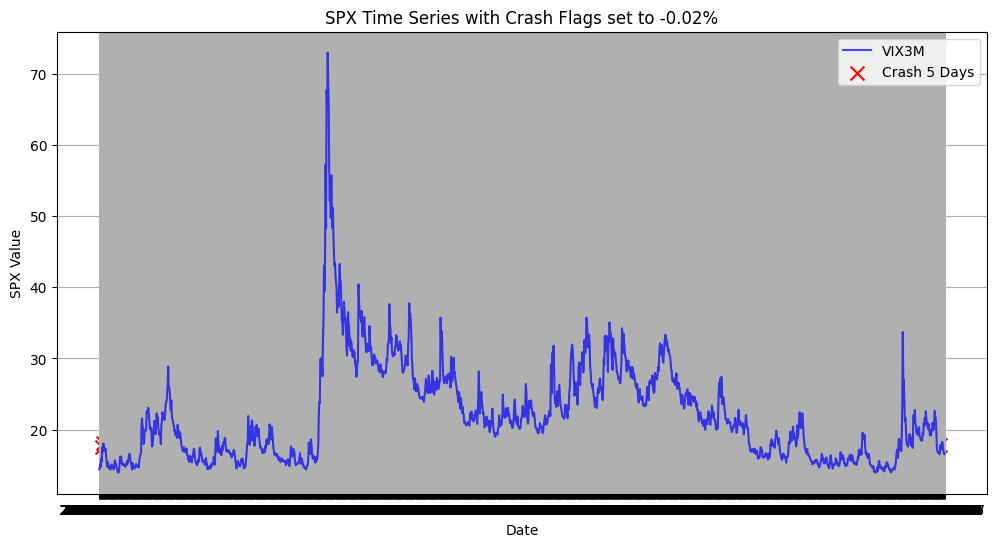

In [53]:
# Plot the SPX time series
plt.figure(figsize=(12, 6))
plt.plot(vix_data.index, vix_data['VIX3M'], label='VIX3M', color='blue', alpha=0.7)

# Highlight dates where crash_1M is 1
crash_dates = vix_data[vix_data['crash_Flag'] == 1]
plt.scatter(crash_dates.index, vix_data.loc[crash_dates.index, 'VIX3M'], color='red', label=crash_label, marker='x', s=100)

# Customize plot
plt.xlabel('Date')
plt.ylabel('SPX Value')
plt.title(f"SPX Time Series with Crash Flags set to {CRASH_FLAG:.2f}%")
plt.legend()
plt.grid(True)
plt.savefig("./results/SPX historical.png", dpi=300, bbox_inches="tight")

In [54]:
crash_ratio= round(vix_data['crash_Flag'].sum()/len(vix_data)*100,2)
print(f"Pourcentage of crashes using the crash flag {CRASH_FLAG:.2f}%: {crash_ratio:.2f}%")

Pourcentage of crashes using the crash flag -0.02%: 14.34%


In [55]:
#vix_data['SPX_pct_change'] = vix_data['SPX'].pct_change()

In [56]:
vix_data.columns

Index(['SPX', 'VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y', 'SPX__OPEN', 'VIX1M_OPEN',
       'VIX3M_OPEN', 'VIX6M_OPEN', 'VIX1Y_OPEN', 'Slope_1M_3M', 'Slope_3M_6M',
       'Slope_6M_1Y', 'SPX_Change', 'VIX1M_Change', 'VIX3M_Change',
       'VIX6M_Change', 'VIX1Y_Change', 'SPX_Same_Day_Change',
       'VIX1M_Same_Day_Change', 'VIX3M_Same_Day_Change',
       'VIX6M_Same_Day_Change', 'VIX1Y_Same_Day_Change',
       'VIX_Significant_Change', 'VIX_Significant_Change_next',
       'VIX_Shift_Prediction', 'VIX_Shift_Prediction_Lag1',
       'VIX_Shift_Prediction_Lag5', 'VIX_Shift_Prediction_Lag2',
       'VIX_Shift_Prediction_Lag3', 'VIX_Shift_Prediction_Lag4', 'crash_Flag',
       'Crash_Flag_Next_Day'],
      dtype='object')

In [57]:
# List of items to remove
drop_columns = [ 'SPX__OPEN','SPX','crash_Flag','SPX_Change','Crash_Flag_Next_Day','VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y','SPX_Same_Day_Change',
       'VIX1M_Same_Day_Change', 'VIX3M_Same_Day_Change',
       'VIX6M_Same_Day_Change', 'VIX1Y_Same_Day_Change',]
#drop_columns = [ 'crash_Flag','Crash_Flag_Next_Day']
# Filter the list
feature_columns = [item for item in vix_data.columns if item not in drop_columns]

### 3.2.2 IMPLEMENT MODEL

In [58]:
vix_data

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX__OPEN,VIX1M_OPEN,VIX3M_OPEN,VIX6M_OPEN,VIX1Y_OPEN,...,VIX_Significant_Change,VIX_Significant_Change_next,VIX_Shift_Prediction,VIX_Shift_Prediction_Lag1,VIX_Shift_Prediction_Lag5,VIX_Shift_Prediction_Lag2,VIX_Shift_Prediction_Lag3,VIX_Shift_Prediction_Lag4,crash_Flag,Crash_Flag_Next_Day
Date,,,,,,,,,,,,,,,,,,,,,
2018-06-15,2779.66,11.98,14.42,16.32,17.54,2777.78,12.19,14.81,16.36,17.50,...,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0
2018-06-18,2773.75,12.31,14.48,16.35,17.61,2765.79,12.79,15.29,16.80,17.93,...,0,0,0,0.0,NaN,NaN,NaN,NaN,0,0
2018-06-19,2762.59,13.35,15.17,16.89,18.09,2752.01,14.61,15.78,17.21,18.19,...,0,0,0,0.0,NaN,0.0,NaN,NaN,0,0
2018-06-20,2767.32,12.79,14.79,16.52,17.77,2769.73,12.90,14.67,16.52,17.75,...,0,0,0,0.0,NaN,0.0,0.0,NaN,0,0
2018-06-21,2749.76,14.64,15.87,17.20,18.18,2769.28,12.54,14.98,16.68,17.86,...,0,0,0,0.0,NaN,0.0,0.0,0.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-21,5948.71,16.87,18.18,19.41,20.63,5940.58,16.54,17.62,18.93,20.54,...,0,0,0,0.0,0.0,0.0,0.0,0.0,0,0
2024-11-22,5969.34,15.24,17.30,18.78,20.26,5944.36,16.85,17.96,19.18,20.63,...,0,0,0,0.0,0.0,0.0,0.0,0.0,0,0
2024-11-25,5987.37,14.60,16.87,18.44,20.06,5992.28,15.23,17.05,18.51,20.04,...,0,0,0,0.0,0.0,0.0,0.0,0.0,0,0


In [59]:
feature_columns

['VIX1M_OPEN',
 'VIX3M_OPEN',
 'VIX6M_OPEN',
 'VIX1Y_OPEN',
 'Slope_1M_3M',
 'Slope_3M_6M',
 'Slope_6M_1Y',
 'VIX1M_Change',
 'VIX3M_Change',
 'VIX6M_Change',
 'VIX1Y_Change',
 'VIX_Significant_Change',
 'VIX_Significant_Change_next',
 'VIX_Shift_Prediction',
 'VIX_Shift_Prediction_Lag1',
 'VIX_Shift_Prediction_Lag5',
 'VIX_Shift_Prediction_Lag2',
 'VIX_Shift_Prediction_Lag3',
 'VIX_Shift_Prediction_Lag4']

In [60]:
# Define features and target for Stage 2
X_stage2 = vix_data[feature_columns]
y_stage2 = vix_data['Crash_Flag_Next_Day']

# Drop rows with NaN values from lagged features
X_stage2 = X_stage2.dropna()
y_stage2 = y_stage2[X_stage2.index]



In [61]:
# Define the split point for 80-20
split_point = int(len(X_stage2) * 0.8)

# Split the data
X_train_stage2 = X_stage2.iloc[:split_point]  # First 80% for training
X_test_stage2 = X_stage2.iloc[split_point:]   # Last 20% for testing
y_train_stage2= y_stage2.iloc[:split_point]  # First 80% for training
y_test_stage2=y_stage2.iloc[split_point:]   # Last 20% for testing

# Display split sizes
print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")
y_benchmark = data['SPX'].iloc[split_point:]

Training set size: 1294
Test set size: 324


In [62]:
# Train the model
# Calculate class imbalance ratio
imbalance_ratio = len(y_train_stage2[y_train_stage2 == 0]) / len(y_train_stage2[y_train_stage2 == 1])

# Adjust the model with scale_pos_weight
stage2_model = XGBClassifier(random_state=42, scale_pos_weight=imbalance_ratio)
stage2_model.fit(X_train_stage2, y_train_stage2)

# Evaluate the model
y_pred_stage2 = stage2_model.predict(X_test_stage2)
print("Accuracy:", accuracy_score(y_test_stage2, y_pred_stage2))
print("Classification Report:\n", classification_report(y_test_stage2, y_pred_stage2))


Accuracy: 0.9071207430340558
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.94      0.95       293
           1       0.50      0.57      0.53        30

    accuracy                           0.91       323
   macro avg       0.73      0.75      0.74       323
weighted avg       0.91      0.91      0.91       323



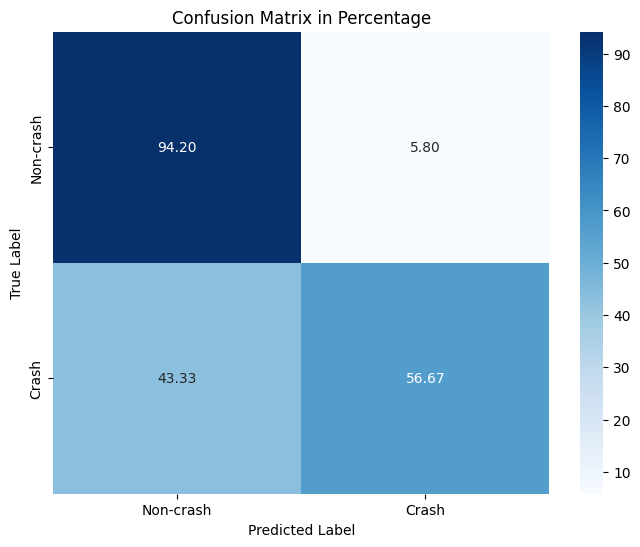

In [63]:
# Calculate the confusion matrix
conf_matrix = confusion_matrix(y_test_stage2, y_pred_stage2)

# Normalize the confusion matrix
conf_matrix_normalized = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]

# Plot the normalized confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_normalized * 100, annot=True, fmt='.2f', cmap='Blues', xticklabels=['Non-crash', 'Crash'], yticklabels=['Non-crash', 'Crash'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix in Percentage')

# Save the figure
plt.savefig("./results/confusion_matrix_percentage.png", dpi=300, bbox_inches="tight")  # Save with high resolution and tight bounding box
#plt.show()



No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


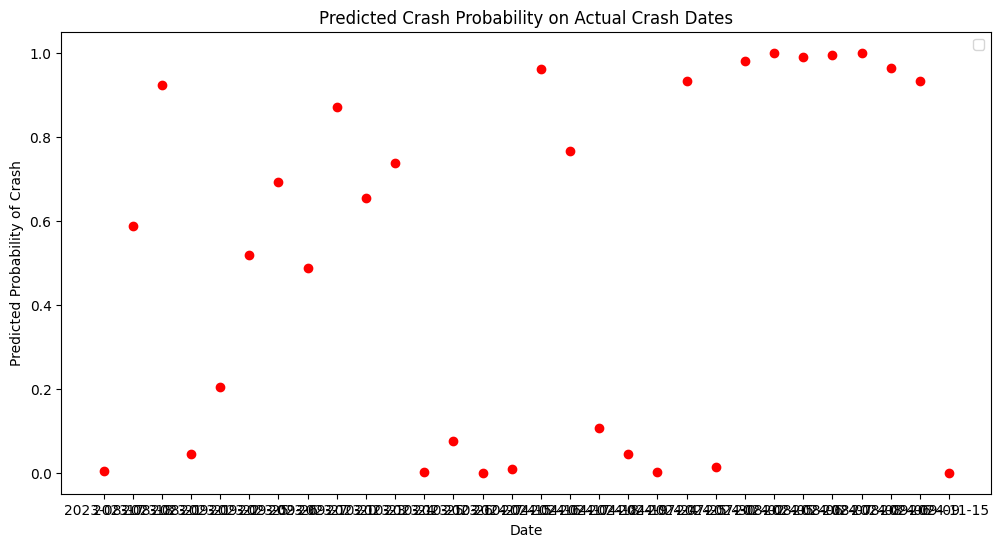

In [64]:
# Get predicted probabilities for the "crash" class (usually the second column of predict_proba output)
proba_crash = stage2_model.predict_proba(X_test_stage2)[:, 1]

# Create a DataFrame for easier plotting
results = pd.DataFrame({
    'Date': X_test_stage2.index,            # Assuming 'Date' is the index
    'Crash_Probability': proba_crash,       # Predicted probability of crash
    'Actual_Crash': y_test_stage2           # Actual crash labels
})


# Filter the data to include only the dates where a crash actually occurred
crash_dates = results[results['Actual_Crash'] == 1]

# Plot the predicted crash probabilities on actual crash dates
plt.figure(figsize=(12, 6))
plt.scatter(crash_dates['Date'], crash_dates['Crash_Probability'], color='red')
plt.xlabel('Date')
plt.ylabel('Predicted Probability of Crash')
plt.title('Predicted Crash Probability on Actual Crash Dates')
plt.legend()
#plt.show()
plt.savefig("./results/Predictions.png", dpi=300, bbox_inches="tight")  # Save with high resolution and tight bounding box


In [65]:
tscv = TimeSeriesSplit(n_splits=5)
scores = cross_val_score(stage2_model, X_stage2, y_stage2, cv=tscv, scoring='accuracy')
print("TimeSeriesSplit Cross-Validation Accuracy Scores:", scores)
print("Mean CV Accuracy:", scores.mean())

TimeSeriesSplit Cross-Validation Accuracy Scores: [0.89179104 0.89179104 0.79477612 0.8619403  0.92537313]
Mean CV Accuracy: 0.8731343283582088


In [66]:
# Assuming y_test_stage2 and y_pred_stage2 are available
precision = precision_score(y_test_stage2, y_pred_stage2, pos_label=1)
recall = recall_score(y_test_stage2, y_pred_stage2, pos_label=1)
f1 = f1_score(y_test_stage2, y_pred_stage2, pos_label=1)

print("Precision (Crash Class):", precision)
print("Recall (Crash Class):", recall)
print("F1-Score (Crash Class):", f1)

Precision (Crash Class): 0.5
Recall (Crash Class): 0.5666666666666667
F1-Score (Crash Class): 0.53125


# 4. BACKTEST THE STRATEGY

In [67]:
X_test_stage2.index

Index(['2023-08-17', '2023-08-18', '2023-08-21', '2023-08-22', '2023-08-23',
       '2023-08-24', '2023-08-25', '2023-08-28', '2023-08-29', '2023-08-30',
       ...
       '2024-11-14', '2024-11-15', '2024-11-18', '2024-11-19', '2024-11-20',
       '2024-11-21', '2024-11-22', '2024-11-25', '2024-11-26', '2024-11-27'],
      dtype='object', name='Date', length=323)

In [68]:
results

,Date,Crash_Probability,Actual_Crash
Date,,,
2023-08-17,2023-08-17,0.003518,1
2023-08-18,2023-08-18,0.587334,1
2023-08-21,2023-08-21,0.921737,1
2023-08-22,2023-08-22,0.000882,0
2023-08-23,2023-08-23,0.001144,0
...,...,...,...
2024-11-21,2024-11-21,0.007814,0
2024-11-22,2024-11-22,0.000323,0
2024-11-25,2024-11-25,0.000028,0


In [69]:
backtest_data=pd.DataFrame(data['SPX'])

In [70]:
#backtest_data['Daily_Returns'] = backtest_data['SPX'].pct_change()
# Calculate percentage change between today and the next day
backtest_data['Daily_Returns'] = (backtest_data['SPX'].shift(-1) - backtest_data['SPX']) / backtest_data['SPX']

In [71]:
backtest_data

,SPX,Daily_Returns
Date,,
2018-06-08,2779.03,0.001069
2018-06-11,2782.00,0.001743
2018-06-12,2786.85,-0.004026
2018-06-13,2775.63,0.002472
2018-06-14,2782.49,-0.001017
...,...,...
2024-11-21,5948.71,0.003468
2024-11-22,5969.34,0.003020
2024-11-25,5987.37,0.005722


In [72]:
merged_data = pd.merge(results, backtest_data, left_index=True, right_index=True, how='inner')  # Inner join

In [73]:
merged_data

,Date,Crash_Probability,Actual_Crash,SPX,Daily_Returns
Date,,,,,
2023-08-17,2023-08-17,0.003518,1,4370.36,-0.000149
2023-08-18,2023-08-18,0.587334,1,4369.71,0.006879
2023-08-21,2023-08-21,0.921737,1,4399.77,-0.002777
2023-08-22,2023-08-22,0.000882,0,4387.55,0.011045
2023-08-23,2023-08-23,0.001144,0,4436.01,-0.013458
...,...,...,...,...,...
2024-11-21,2024-11-21,0.007814,0,5948.71,0.003468
2024-11-22,2024-11-22,0.000323,0,5969.34,0.003020
2024-11-25,2024-11-25,0.000028,0,5987.37,0.005722


In [74]:
merged_data['Adjusted_Daily_Returns'] = merged_data.apply(
    lambda row: 0 if row['Crash_Probability'] >= 0.5 else row['Daily_Returns'], axis=1
)

In [78]:
merged_data.dropna(inplace=True)

In [79]:
# Initialize the starting index value
initial_index_value = 100

# Create the Index based on Daily_Returns
merged_data['Daily_Return_Index'] = initial_index_value * (1 + merged_data['Daily_Returns']).cumprod()

# Create the Index based on Adjusted_Daily_Returns
merged_data['Adjusted_Daily_Return_Index'] = initial_index_value * (1 + merged_data['Adjusted_Daily_Returns']).cumprod()



In [80]:
# Display results
print("Final Benchmark Return:", merged_data['Daily_Return_Index'].iloc[-1])
print("Final Strategy Return:", merged_data['Adjusted_Daily_Return_Index'].iloc[-1])

Final Benchmark Return: 137.25963078556484
Final Strategy Return: 132.66747157655928


In [81]:
merged_data

,Date,Crash_Probability,Actual_Crash,SPX,Daily_Returns,Adjusted_Daily_Returns,Daily_Return_Index,Adjusted_Daily_Return_Index
Date,,,,,,,,
2023-08-17,2023-08-17,0.003518,1,4370.36,-0.000149,-0.000149,99.985127,99.985127
2023-08-18,2023-08-18,0.587334,1,4369.71,0.006879,0.000000,100.672942,99.985127
2023-08-21,2023-08-21,0.921737,1,4399.77,-0.002777,0.000000,100.393331,99.985127
2023-08-22,2023-08-22,0.000882,0,4387.55,0.011045,0.011045,101.502165,101.089452
2023-08-23,2023-08-23,0.001144,0,4436.01,-0.013458,-0.013458,100.136144,99.728986
...,...,...,...,...,...,...,...,...
2024-11-20,2024-11-20,0.003686,0,5917.11,0.005340,0.005340,136.114874,131.561014
2024-11-21,2024-11-21,0.007814,0,5948.71,0.003468,0.003468,136.586917,132.017264
2024-11-22,2024-11-22,0.000323,0,5969.34,0.003020,0.003020,136.999469,132.416014


In [82]:
# Calculate the standard deviation of daily returns
std_daily_returns = merged_data['Daily_Returns'].std()
std_daily_returns_adjusted = merged_data['Adjusted_Daily_Returns'].std()
# Display results
print(f"Standard Deviation of Daily Returns: {std_daily_returns}")
print(f"Standard Deviation of Daily Returns adjusted: {std_daily_returns_adjusted}")

Standard Deviation of Daily Returns: 0.007838703226331291
Standard Deviation of Daily Returns adjusted: 0.006970857927367921


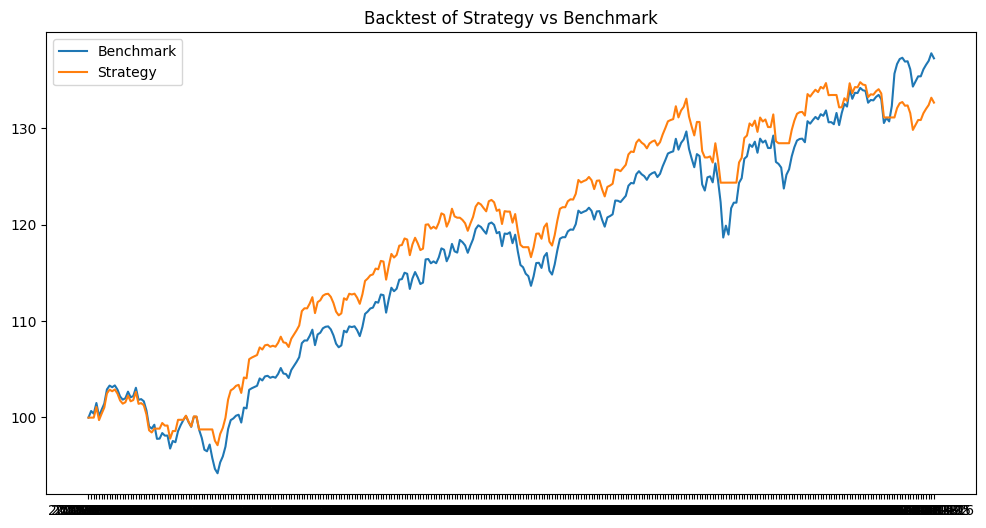

In [83]:
plt.figure(figsize=(12, 6))
plt.plot(merged_data['Daily_Return_Index'], label='Benchmark')
plt.plot(merged_data['Adjusted_Daily_Return_Index'], label='Strategy')
plt.legend()
plt.title("Backtest of Strategy vs Benchmark")
plt.savefig("./results/AI_backtest.png", dpi=300, bbox_inches="tight")
plt.show()


In [72]:
merged_data

,Date,Crash_Probability,Actual_Crash,SPX,Daily_Returns,Adjusted_Daily_Returns,Daily_Return_Index,Adjusted_Daily_Return_Index
Date,,,,,,,,
2023-08-14,2023-08-14,0.000393,0.0,4489.72,-0.011551,-0.011551,98.844917,98.844917
2023-08-15,2023-08-15,0.000617,0.0,4437.86,-0.007555,-0.007555,98.098100,98.098100
2023-08-16,2023-08-16,0.029119,1.0,4404.33,-0.007713,-0.007713,97.341482,97.341482
2023-08-17,2023-08-17,0.425490,1.0,4370.36,-0.000149,0.000000,97.327005,97.341482
2023-08-18,2023-08-18,0.008099,1.0,4369.71,0.006879,0.006879,97.996534,98.011111
...,...,...,...,...,...,...,...,...
2024-11-15,2024-11-15,0.021264,0.0,5870.62,0.003918,0.003918,131.269211,131.047256
2024-11-18,2024-11-18,0.010546,0.0,5893.62,0.003964,0.003964,131.789510,131.566676
2024-11-19,2024-11-19,0.477484,0.0,5916.98,0.000022,0.000000,131.792406,131.566676


In [80]:
len(merged_data[merged_data['Actual_Crash'] ==1])/len(merged_data)

0.09316770186335403

In [81]:
len(merged_data[merged_data['Crash_Probability'] > 0.5])/len(merged_data)

0.09627329192546584

In [74]:
merged_data[merged_data['Crash_Probability'] > 0.5]

,Date,Crash_Probability,Actual_Crash,SPX,Daily_Returns,Adjusted_Daily_Returns,Daily_Return_Index,Adjusted_Daily_Return_Index
Date,,,,,,,,
2023-09-21,2023-09-21,0.876011,1.0,4330.00,-0.002296,0.0,96.221145,96.456886
2023-09-22,2023-09-22,0.563929,1.0,4320.06,0.004023,0.0,96.608252,96.456886
2023-09-25,2023-09-25,0.707259,1.0,4337.44,-0.014734,0.0,95.184778,96.456886
2023-09-26,2023-09-26,0.895781,1.0,4273.53,0.000229,0.0,95.206605,96.456886
2023-10-05,2023-10-05,0.963036,0.0,4258.19,0.011815,0.0,95.963668,95.525675
2023-10-19,2023-10-19,0.846525,1.0,4278.00,-0.012585,0.0,94.085155,94.849446
2023-10-20,2023-10-20,0.998379,1.0,4224.16,-0.001686,0.0,93.926570,94.849446
2023-10-23,2023-10-23,0.841265,1.0,4217.04,0.007266,0.0,94.609018,94.849446
2023-10-26,2023-10-26,0.639138,1.0,4137.23,-0.004800,0.0,91.706610,92.383130
